Before you turn this problem in, make sure everything runs as expected. First, **restart the kernel** (in the menubar, select Kernel$\rightarrow$Restart) and then **run all cells** (in the menubar, select Cell$\rightarrow$Run All).

Make sure you fill in any place that says `YOUR CODE HERE` or "YOUR ANSWER HERE", as well as your name and collaborators below:

In [ ]:
NAME = ""
COLLABORATORS = ""

---

### 量化交易策略实战：从入门到回测

分享人：高麒越，曾屹龙，赵宇哲

内容：使用api， 结合多种经典交易策略，利用Python进行回测与分析


#### **一、 API的定义**

**API**，全称为 **Application Programming Interface**，中文译作“**应用程序编程接口**”。

从技术层面定义，API是一套预先定义好的规则、协议、类和工具的集合，它明确规定了不同软件组件之间进行交互和通信的方式。它本质上是一个**抽象层**，允许一个软件应用程序使用另一个软件的功能或数据，而无需了解其内部的复杂实现细节。

为了便于理解，我们可以将其比作一个**标准化的电气插座**。全世界的电力系统（后端服务）极其复杂，但我们无需理解发电、变电和输电的原理。我们只需要一个符合标准的插头（客户端请求），就可以通过插座（API）这个标准接口，安全、稳定地获取电力（服务或数据）。API就是软件世界中的“插座”，它提供了一个清晰的“契约”，定义了可以请求什么、如何请求，以及会得到什么样的返回结果。

#### **二、 API的用途**

API在现代软件工程和数据科学中扮演着至关重要的角色，其核心用途可归纳为以下几点：

1.  **实现抽象与封装**：API将复杂的系统功能封装起来，只暴露有限且必要的接口。开发者可以像使用积木一样调用这些功能，极大地提高了开发效率。在量化金融中，我们调用`bs.login()`登录BaoStock，无需关心其背后网络连接、认证、会话管理的复杂过程，这就是抽象化的体现。

2.  **促进模块化与互操作性**：API使得软件系统可以被拆分成独立的、可复用的模块。不同的团队、甚至不同的公司，只要遵循相同的API协议，就可以协同开发。这使得您的Python策略（一个模块）能够与券商的交易系统（另一个模块）或Tushare、BaoStock的数据服务（第三方模块）进行无缝通信。

3.  **提供受控的数据与功能访问**：API是数据和功能所有者（服务提供方）的“守门人”。它确保了外部调用者只能在授权范围内、以规定的方式访问资源。这对于商业数据提供商尤为重要，API可以帮助他们实现用户认证、流量控制、计费和安全保障。

4.  **在量化金融领域的具体应用**：
    * **数据获取**：这是最核心的用途。通过数据提供商（如BaoStock, Tushare, Wind）的API，获取股票、期货、期权等资产的历史K线、财务报表、宏观经济等数据。
    * **交易执行**：通过券商提供的交易API（CTP接口是期货领域的典型代表），实现自动化下单、撤单、查询持仓和资金状况。
    * **平台集成**：将本地开发的策略模型通过API对接到专业的量化平台（如聚宽、米筐）或自己搭建的系统中，实现策略的托管和自动化运行。

---

#### **一、 BaoStock的定义**

**BaoStock**是一个**免费、开源的Python库**。它本身不是原始数据源，而是一个功能强大的**API客户端**。其核心定位是为中国的量化交易研究者、特别是个人开发者和学术研究人员，提供一个稳定、快速、便捷的接口，用以获取**中国A股市场的证券历史数据**。

从技术架构上看，BaoStock库是连接用户本地Python环境与BaoStock远程数据服务器之间的桥梁。它封装了所有底层的网络通信、数据请求和解析过程，将复杂的数据获取任务简化为几个简单的Python函数调用。

#### **二、 BaoStock的用途**

BaoStock作为一个专注于A股历史数据的API，其主要用途是为量化交易的全流程研究提供基础支持：

1.  **全面的历史数据获取**：BaoStock为策略研发提供了丰富的“原材料”，主要包括：
    * **行情数据**：提供A股、指数、ETF等标的日线及分钟级别的K线数据（OHLC、成交量、成交额、换手率等），并且原生支持**前复权**和**后复权**数据的获取，这对于构建依赖价格形态的技术分析策略至关重要。
    * **公司基本面数据**：提供上市公司的盈利能力、成长能力、营运能力、估值水平等关键财务指标，是构建基本面选股、价值投资等策略的数据基础。
    * **其他关键数据**：包括宏观经济数据（如存款准备金率）、行业分类数据、指数成分股、融资融券数据等，为多维度、深层次的策略研究提供了可能。

2.  **支持策略开发与回测**：BaoStock的核心价值在于为策略回测提供数据输入。其API返回的数据格式可以与**Pandas**库无缝集成，轻松转换为DataFrame结构。这使得研究人员可以非常高效地对数据进行清洗、计算指标、构建交易逻辑并进行历史回测，从而科学地评估交易策略的有效性。

3.  **赋能学术研究与教学**：由于其**免费和开源**的特性，BaoStock极大地降低了高校师生及个人研究者进行中国市场实证金融研究的门槛。它为金融工程、计算金融等课程提供了理想的数据支持，使理论学习能够与编程实践紧密结合。

4.  **作为金融分析应用的数据后端**：对于需要开发轻量级金融数据分析工具、股票筛选器或可视化仪表盘的个人项目，BaoStock可以作为一个稳定可靠的后端数据源。

**总结而言**，BaoStock通过提供一个专业且免费的**API**，将复杂的A股历史数据获取过程标准化、简单化，使量化研究者能够摆脱繁琐的数据工作，将精力更加集中于策略的构建、验证和优化这一核心任务上。

In [ ]:
# 导入所需的库
import baostock as bs
import pandas as pd

# --- 1. 登录系统 ---
# login()函数用于登录BaoStock服务器，建立连接
lg = bs.login()

# 检查登录是否成功
# msg和code是服务器返回的信息，code为'0'代表成功
if lg.error_code != '0':
    print(f"登录失败，错误代码: {lg.error_code}")
    print(f"错误信息: {lg.error_msg}")
else:
    print("登录成功！")

    # --- 2. 准备查询参数 ---
    stock_code = "sh.600519"  # 股票代码：sh代表上海交易所，600519是贵州茅台
    start_date = "2024-01-01"  # 开始日期
    end_date = "2024-12-31"    # 结束日期
    
    # 定义要查询的字段
    # 更多字段请参考BaoStock官方文档
    fields = "date,code,open,high,low,close,volume,amount,turn"
    
    # --- 3. 发送API请求，获取K线数据 ---
    # query_history_k_data_plus() 是获取K线数据的核心函数
    # frequency='d'代表日线, adjustflag='2'代表前复权
    rs = bs.query_history_k_data_plus(stock_code, fields,
                                      start_date=start_date, end_date=end_date,
                                      frequency="d", adjustflag="2")

    # 检查查询是否成功
    if rs.error_code != '0':
        print(f"查询K线数据失败，错误代码: {rs.error_code}")
        print(f"错误信息: {rs.error_msg}")
    else:
        # --- 4. 处理返回结果 ---
        data_list = []
        # rs.next() 用于逐行读取服务器返回的数据
        while (rs.error_code == '0') & rs.next():
            data_list.append(rs.get_row_data())
        
        # 将数据列表转换为Pandas DataFrame
        df = pd.DataFrame(data_list, columns=rs.fields)
        
        # --- 5. 数据清洗和转换 ---
        # BaoStock返回的数据都是字符串格式，需要转换为正确的数值类型
        df['open'] = pd.to_numeric(df['open'])
        df['high'] = pd.to_numeric(df['high'])
        df['low'] = pd.to_numeric(df['low'])
        df['close'] = pd.to_numeric(df['close'])
        df['volume'] = pd.to_numeric(df['volume'])
        df['amount'] = pd.to_numeric(df['amount'])
        df['turn'] = pd.to_numeric(df['turn'])
        df['date'] = pd.to_datetime(df['date'])
        
        # 将date列设为索引
        df.set_index('date', inplace=True)

        # 打印DataFrame的前5行，查看结果
        print("\n获取到的贵州茅台前复权日K线数据：")
        print(df.head())

# --- 6. 登出系统 ---
# 操作结束后，务必登出，释放连接资源
bs.logout()
print("\n已登出系统。")

### MACD指标全面详解：从入门到精通

MACD（Moving Average Convergence Divergence）指标，中文全称为**指数平滑异同移动平均线**，是技术分析中最常用、最经典的指标之一。它不仅能判断市场的趋势方向，还能衡量动能的强弱，帮助交易者发现潜在的买卖时机。

---

MACD由杰拉尔德·阿佩尔（Gerald Appel）在1970年代后期发明。

他的核心洞察是：**资产价格的趋势变化（无论是开始、加速还是减速）可以通过观察不同速度的趋势线（即移动平均线）之间的关系来捕捉。**

他想创造一个**既能跟踪趋势，又能识别动量Momentum**的指标。

**拆解MACD的“为什么”：**

1. **为什么选择“移动平均线”（MA）？**

- **目的：** 消除短期噪音，看清长期趋势。
- **逻辑：** 股价每天都在波动，MA通过计算一段时间的平均价格，将这些“毛刺”抹平，展现出一条更平滑的趋势线。
2. **为什么是“指数”移动平均线（EMA），而不是简单移动平均线（SMA）？**

- **目的：** 让指标对*近期*的价格变化更敏感。
- **逻辑：** SMA对窗口期内的所有价格（比如26天）一视同仁。而Appel认为，*最近*发生的价格行为（昨天的价格）比25天前的价格更重要。EMA通过加权算法，给予近期价格更高的权重。这使得EMA能比SMA更快地对价格转向做出反应。
3. **为什么是“12周期”和“26周期”？**

- **目的：** 捕捉“短期动量”和“中期趋势”的关系。
- **逻辑：**

**EMA(12)**：代表一个较短期的趋势（大约两周半）。它像一艘快艇，紧跟价格。

**EMA(26)**：代表一个较中期的趋势（大约一个月）。它像一艘货轮，行驶得更平稳。
- （*注：这些数字最初是为日线图设计的，可以调整以适应不同市场或时间周期。*）
4. **为什么“相减”？（MACD线 = EMA(12) - EMA(26)）**

- **目的：** **将“趋势跟踪”转化为“动量震荡”。**
- **逻辑：**

当短期趋势（快艇）比中期趋势（货轮）跑得快时（即EMA(12) &gt; EMA(26)），市场处于**上升动量**中。相减的结果（MACD线）将是一个正数，并远离0线。

当短期趋势开始掉头，慢于中期趋势时（EMA(12) &lt; EMA(26)），市场处于**下降动量**中。相减的结果（MACD线）将是一个负数。

**这步操作是天才之举。** 它不再显示两条线，而是显示了**这两条线之间的距离**。这个“距离”本身就是**动量**的直接度量。距离越大，动量越强。
5. **为什么要有信号线？**

- **目的：** 寻找动量*本身*的“拐点”，即产生交易信号。
- **逻辑：** MACD线（那条代表动量的线）本身还是有波动。为了找到一个更可靠的买卖点，Appel想：“我能不能再对这条动量线做一次平滑？”
- 于是，他计算了MACD线*自己*的9周期EMA，称之为“信号线”。
- **“金叉” (MACD线上穿信号线):** 意味着原始动量（MACD线）开始*加速*，超过了它自己的短期平均值（信号线）。这是一个**动量增强**的信号（买入）。
- **“死叉” (MACD线下穿信号线):** 意味着原始动量开始*减速*，跌破了它自己的短期平均值。这是一个**动量减弱**的信号（卖出）。
6. **为什么要有“柱状图”（Histogram = MACD线 - 信号线）？**

- **目的：** 更直观地展示动量的“加速度”。
- **逻辑：** 柱状图就是MACD线和信号线之间的距离。

当柱状图在0轴上方（正值）并不断**变长**时，说明上升动量在**加速**。

当柱状图在0轴上方但开始**缩短**时，说明上升动量在**减速**（这是顶背离的雏形）。

当柱状图在0轴下方（负值）并不断**变长**时，说明下降动量在**加速**。

当柱状图在0轴下方但开始**缩短**时，说明下降动量在**减速**（这是底背离的雏形）。

**总结：如果你要创造MACD**

你会这样思考：
“我需要一个指标，能告诉我趋势，还能告诉我趋势的力道（动量）。

1. 我用两条快慢EMA（12和26）来定义趋势。
2. 我把它们相减（MACD线），这个差值就是‘动量’。
3. 我再用一条EMA（9）来平滑这个‘动量’（信号线），用它们的交叉来告诉我‘动量’何时发生了转向，作为买卖信号。
4. 最后，我把‘动量’和它的‘平滑线’再相减（柱状图），这样我连‘动量’的‘加速度’都能看清了。”


---

### 二、 核心概念与组成部分

MACD的本质是利用两条不同速度的指数移动平均线（EMA）的离散和聚合程度，来判断价格的动能和趋势变化。它主要由以下三个核心部分组成：

1.  **快线 (DIF Line)**：
    * **定义**：通常称为“差离值”（Difference），由短期EMA减去长期EMA计算得出。
    * **标准参数**：短期为12日EMA，长期为26日EMA。
    * **作用**：反应灵敏，能快速捕捉价格的短期变化。因此被称为“快线”。

2.  **慢线 (DEA Line 或 Signal Line)**：
    * **定义**：通常称为“信号线”（Signal Line）或“离差平均值”（Difference Exponential Average），是快线（DIF）的移动平均线。
    * **标准参数**：通常取DIF的9日EMA。
    * **作用**：对快线进行了平滑处理，反应相对滞后，能帮助过滤掉一些虚假的短期信号，因此被称为“慢线”。

3.  **柱状图 (Histogram 或 OSC)**：
    * **定义**：显示快线（DIF）与慢线（DEA）之间的差距。
    * **计算**：`柱状图 = 快线 (DIF) - 慢线 (DEA)`
    * **作用**：直观地展示多空动能的强弱和消长。
        * **红柱（正值）**：当快线在慢线上方时出现，表示多头动能占优。柱子越长，多头动能越强。
        * **绿柱（负值）**：当快线在慢线下方时出现，表示空头动能占优。柱子越长，空头动能越强。

<br>

**计算公式总结：**
* **快线 (DIF)** = 12日EMA - 26日EMA
* **慢线 (DEA)** = DIF的9日EMA
* **柱状图 (Histogram)** = DIF - DEA

> **什么是EMA？**
> EMA（Exponential Moving Average，指数移动平均线）是一种加权移动平均线。与简单移动平均线（SMA）给予所有数据相同权重不同，EMA给予越近期的价格越高的权重，因此它对价格变动的反应比SMA更为灵敏。

---

### 三、 核心应用：如何使用MACD进行交易

MACD的应用方法多样，以下是四种最核心的分析技巧：

#### 1. 交叉信号 (Crossovers)

这是MACD最基础也是最常见的用法，通过观察快线和慢线的交叉来判断买卖信号。

* **黄金交叉 (Golden Cross) - 买入信号**
    * **形态**：快线（DIF）由下向上穿过慢线（DEA）。
    * **解读**：表明市场趋势可能由跌转涨，多头力量开始增强，是潜在的**买入信号**。此时，柱状图通常由绿翻红（由负转正）。
    * **信号强度**：如果交叉发生在零轴下方，信号通常更为可靠，预示着一轮上涨行情可能开启。

* **死亡交叉 (Death Cross) - 卖出信号**
    * **形态**：快线（DIF）由上向下穿过慢线（DEA）。
    * **解读**：表明市场趋势可能由涨转跌，空头力量开始占优，是潜在的**卖出信号**。此时，柱状图通常由红翻绿（由正转负）。
    * **信号强度**：如果交叉发生在零轴上方，信号通常更为可靠，预示着一轮下跌行情可能开启。

#### 2. 零轴分析 (Zero-Line Analysis)

零轴是MACD图中的多空分界线，可以用来判断市场的整体趋势。

* **站上零轴**：当DIF和DEA线同时运行在零轴**上方**时，表明市场处于**多头趋势**。此时应以做多或持有多单为主，谨慎做空。
* **跌破零轴**：当DIF和DEA线同时运行在零轴**下方**时，表明市场处于**空头趋势**。此时应以做空或持有空单为主，谨慎做多。

#### 3. 背离 (Divergence)

背离是MACD最强大的信号之一，通常预示着趋势即将反转。它是指价格走势和指标走势出现了不一致的现象。

* **底背离 (Bullish Divergence) - 趋势看涨信号**
    * **形态**：价格创出新低，但MACD指标的低点却在抬高（未创出新低）。
    * **解读**：这表明虽然价格仍在下跌，但下跌的动能已经减弱，空头力量衰竭，市场可能即将**见底反弹**。这是强烈的潜在**买入信号**。

* **顶背离 (Bearish Divergence) - 趋势看跌信号**
    * **形态**：价格创出新高，但MACD指标的高点却在降低（未创出新高）。
    * **解读**：这表明虽然价格仍在上涨，但上涨的动能已经不足，多头力量衰竭，市场可能即将**见顶回落**。这是强烈的潜在**卖出信号**。

#### 4. 柱状图分析 (Histogram Analysis)

柱状图的长短和颜色变化，直观地反映了动能的变化，可以用于确认趋势和寻找交易点。

* **柱状图长度**：柱子越长，代表当前趋势的动能越强。反之，柱子缩短，则意味着动能减弱，趋势可能放缓或反转。
* **红绿翻转**：柱状图从绿色变为红色，是黄金交叉的确认；从红色变为绿色，是死亡交叉的确认。

---

### 四、 优点与局限性

**优点：**
* **兼具趋势与动能**：既能判断趋势方向，也能衡量动能强弱。
* **直观易懂**：交叉、背离等信号清晰，对新手友好。
* **适用性广**：适用于股票、外汇、期货等多种市场和不同时间周期。

**局限性：**
* **滞后性**：MACD是基于历史价格计算的，因此信号会有所延迟，可能错过最佳入场点。
* **震荡市失灵**：在没有明显趋势的横盘震荡行情中，MACD会频繁发出金叉和死叉的假信号，参考价值降低。

### 总结

MACD是一个功能强大且非常实用的技术指标。要发挥其最大效用，建议不要单独使用，而是将其与其他分析工具（如趋势线、支撑阻力位、K线形态、RSI指标等）结合，进行综合判断，这样可以大大提高交易的胜率。对于新手而言，从理解和应用MACD的交叉和背离开始，是迈向成熟技术分析的重要一步。

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# --- 1. 加载和准备数据 ---
try:
    # 读取Excel文件，并将'Date'列设为索引，同时解析为日期格式
    df = pd.read_excel('amd_data.xlsx', index_col='Date', parse_dates=True)
except FileNotFoundError:
    print("错误：'amd_data.xlsx' 文件未找到。请确保该文件与脚本在同一目录下。")
    exit()

# --- 2. 计算MACD指标 ---
# 设置MACD参数
short_ema_period = 12
long_ema_period = 26
signal_period = 9

# 计算短期和长期的指数移动平均线 (EMA)
# adjust=False 参数使其计算方式与大多数交易平台一致
df['EMA12'] = df['Adj Close'].ewm(span=short_ema_period, adjust=False).mean()
df['EMA26'] = df['Adj Close'].ewm(span=long_ema_period, adjust=False).mean()

# 计算MACD线 (DIF)
df['MACD'] = df['EMA12'] - df['EMA26']

# 计算信号线 (DEA)
df['Signal_Line'] = df['MACD'].ewm(span=signal_period, adjust=False).mean()

# 计算MACD柱状图 (Histogram)
df['Histogram'] = df['MACD'] - df['Signal_Line']


# --- 3. 绘制图表 ---
# 创建一个包含两个子图的图表（上下排列），并共享X轴
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 10), sharex=True)

# 设置整体标题
fig.suptitle('AMD price and MACD analysis', fontsize=20)

# --- 子图1: 价格图 ---
ax1.plot(df.index, df['Adj Close'], label='AMD Adj Close', color='skyblue')
ax1.set_title('AMD Adjusted Close Price', fontsize=14)
ax1.set_ylabel('Price ($)', fontsize=12)
ax1.legend()
ax1.grid(True, linestyle='--', alpha=0.6)

# --- 子图2: MACD指标图 ---
# 绘制MACD线和信号线
ax2.plot(df.index, df['MACD'], label='MACD Line (DIF)', color='orange')
ax2.plot(df.index, df['Signal_Line'], label='Signal Line (DEA)', color='red', linestyle='--')

# 绘制柱状图，并根据正负值设置不同颜色
colors = ['g' if val >= 0 else 'r' for val in df['Histogram']]
ax2.bar(df.index, df['Histogram'], label='Histogram', color=colors, alpha=0.7)

# 添加0轴水平线
ax2.axhline(0, color='grey', linestyle='--')

ax2.set_title('MACD Indicator', fontsize=14)
ax2.set_ylabel('Value', fontsize=12)
ax2.set_xlabel('Date', fontsize=12)
ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.6)

# 优化X轴日期的显示格式
ax2.xaxis.set_major_locator(mdates.AutoDateLocator())
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
fig.autofmt_xdate() # 自动旋转日期标签，防止重叠

# 调整布局，防止标题重叠
plt.tight_layout(rect=[0, 0, 1, 0.96])

# 显示图表
plt.show()


### 1. 实例分析：经典的“底背离” (Bullish Divergence)

请看图表的中间部分，我为你标出了一个完美的“教科书级别”的例子：

- **时间**：大约在 **2025年4月 到 2025年5月** 之间。
- **看价格 (上图)**：AMD的股价在4月创下了一个低点（约 $90），然后在5月创下了**一个更低的低点**（约 $80）。按照趋势，这看起来非常悲观，似乎要继续下跌。
- **看MACD (下图)**：在同一时间段，MACD线（橙色线）在4月创下了一个低点（约 -7.5），但**在5月股价创新低时，MACD却创下了一个更高的低点**（约 -6）。
- **分析**：这就是我们所说的**底背离**。

**背后的逻辑**：价格虽然在下跌，但MACD（代表动量）显示下跌的“力道”已经衰竭了（动量在减弱）。卖方正在失去动力。

**真相**：如图所示，在这次底背离之后，一个“金叉”（橙线上穿红线）随之出现，AMD的股价**迎来了一波强劲的主升浪**，从$80一路涨到了$180以上。

### 2. 实例分析：“顶背离” (Bearish Divergence)

现在，我们看图表的后半部分：

- **时间**：大约在 **2025年8月 到 2025年9月** 之间。
- **看价格 (上图)**：股价在8月创下了一个高点（约 $185），之后回落，在9月再次强势反弹至一个**几乎相同的高点**（约 $180）。
- **看MACD (下图)**：在同一时间段，MACD线在8月创下了高点（约 2.5），但**在9月股价反弹时，MACD的高点却明显降低了**（约 2.0）。
- **分析**：这就是**顶背离**。

**背后的逻辑**：价格虽然还维持在高位，但MACD显示上涨的“力道”已经跟不上了（动量在减弱）。买方后继乏力。

**真相**：顶背离出现后，一个“死叉”（橙线下穿红线）发生，股价**随之开始了一波显著的回调**。

### 3. 实例分析：柱状图 (Histogram) 的作用

柱状图（绿色和红色）是动量的“加速度”计。

- **看 2025年5月到7月（上涨期）**：

刚开始（5月底），绿色柱状图不断**变长**，代表上涨动能在**加速**。

到了7月中旬，虽然价格还在涨，但绿色柱状图开始**缩短**，代表上涨动能在**减速**（这是顶背离的早期预警）。
- **看 2025年9月后（下跌期）**：

刚开始（9月中），红色柱状图不断**变长**，代表下跌动能在**加速**。

到了10月初，红色柱状图开始**缩短**，代表下跌动能在**减速**（这是底背离的早期预警）。


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
#这个函数负责计算两条简单移动平均线 (SMA)。
def macd(signals):
    
    
    signals['ma1']=signals['Close'].rolling(window=ma1,min_periods=1,center=False).mean()
    signals['ma2']=signals['Close'].rolling(window=ma2,min_periods=1,center=False).mean()
    
    return signals
#这个函数负责生成交易信号。
def signal_generation(df,method):
    
    signals=method(df)
    signals['positions']=0

    #positions becomes and stays one once the short moving average is above long moving average
    signals['positions'][ma1:]=np.where(signals['ma1'][ma1:]>=signals['ma2'][ma1:],1,0)

    #as positions only imply the holding
    #we take the difference to generate real trade signal
    signals['signals']=signals['positions'].diff()

    #oscillator is the difference between two moving average
    #when it is positive, we long, vice versa
    signals['oscillator']=signals['ma1']-signals['ma2']

    return signals


In [ ]:
#这个函数负责将所有计算结果用图表清晰地展示出来。
#plotting the backtesting result
def plot(new, ticker):
    
    #the first plot is the actual close price with long/short positions
    fig=plt.figure()
    ax=fig.add_subplot(111)
    
    new['Close'].plot(label=ticker)
    ax.plot(new.loc[new['signals']==1].index,new['Close'][new['signals']==1],label='LONG',lw=0,marker='^',c='g')
    ax.plot(new.loc[new['signals']==-1].index,new['Close'][new['signals']==-1],label='SHORT',lw=0,marker='v',c='r')

    plt.legend(loc='best')
    plt.grid(True)
    plt.title('Positions')
    
    plt.show()
    
    #the second plot is long/short moving average with oscillator
    #note that i use bar chart for oscillator
    fig=plt.figure()
    cx=fig.add_subplot(211)

    new['oscillator'].plot(kind='bar',color='r')

    plt.legend(loc='best')
    plt.grid(True)
    plt.xticks([])
    plt.xlabel('')
    plt.title('MACD Oscillator')

    bx=fig.add_subplot(212)

    new['ma1'].plot(label='ma1')
    new['ma2'].plot(label='ma2',linestyle=':')
    
    plt.legend(loc='best')
    plt.grid(True)
    plt.show()

下面这是脚本的入口，负责将所有部分串联起来。

* 参数设置: 你可以在这里轻松更改短期/长期均线的周期 (ma1, ma2) 和股票代码 (ticker)。

* 数据加载与处理: 代码从名为 amd_data.xlsx 的 Excel 文件中读取数据，并进行了必要的格式转换和数据清洗。

* 执行与可视化: 最后两行代码是整个流程的触发器，它们调用前面定义的函数，完成计算和绘图。

In [ ]:

# -*- coding: utf-8 -*-
import pandas as pd

# ====== 参数 ======
ma1 = 12
ma2 = 26
ticker = 'AMD'
slicer = 0

# ====== 从 Excel 读取数据 ======
# 请确认文件路径和名称正确
df = pd.read_excel('amd_data.xlsx')

# 显示列名确认
print("✅ Columns:", df.columns.tolist())

# 确保日期列为 datetime 并设为索引
df['Date'] = pd.to_datetime(df['Date'])
df.set_index('Date', inplace=True)

# 清理 Volume 列中的逗号和空格
if 'Volume' in df.columns:
    df['Volume'] = df['Volume'].astype(str).str.replace(',', '').str.strip()
    df['Volume'] = pd.to_numeric(df['Volume'], errors='coerce')



# 检查前几行
print(df.head())

# ====== 运行你的策略函数 ======
new = signal_generation(df, macd)

if isinstance(slicer, int) and slicer > 0:
    new = new.iloc[slicer:]

plot(new, ticker)



### Dual Thrust 策略全面详解

Dual Thrust是一个著名且非常经典的日内交易（Intraday Trading）策略，属于开盘区间突破（Opening Range Breakout）策略的一种。它由迈克尔·查莱克（Michael Chalek）开发，最初主要用于期货市场的日内交易，后来也被广泛应用于股票、外汇等高流动性市场。

---

#### 一、 来源与核心思想

Dual Thrust的核心思想非常直观：**市场在前N天的价格波动中会形成一个特定的“震荡区间”，当今天的价格强势突破这个区间的上轨或下轨时，就意味着日内趋势可能已经形成，此时顺势跟进交易。**

与简单的开盘价突破策略不同，Dual Thrust的“区间”是**动态**的，它基于过去N天的历史价格数据（最高价、最低价、收盘价）来计算，这使得它能更好地适应市场的近期波动性。

该策略最独特的特点是其**非对称性**——它允许你为上轨（做多）和下轨（做空）设置不同的突破敏感度，从而让策略可以带有一点主观的“偏见”（例如，如果你认为今天大盘看涨，可以把做多的触发条件设置得更容易一些）。

---

#### 二、 核心概念与计算方法

Dual Thrust策略的构建主要依赖于以下几个关键值：

1.  **回顾期 (N天)**：这是计算震荡区间的历史天数，是一个需要优化的关键参数。
2.  **四个关键价格**：基于过去N天的K线数据，我们需要找到：
    * `HH` (Highest High): N天内的最高价。
    * `HC` (Highest Close): N天内的最高收盘价。
    * `LC` (Lowest Close): N天内的最低收盘价。
    * `LL` (Lowest Low): N天内的最低价。

3.  **震荡区间 (Range)**：区间的宽度由以下公式确定：
    $$
    \text{Range} = \max(\text{HH} - \text{LC}, \text{HC} - \text{LL})
    $$
    这个公式的巧妙之处在于，它同时考虑了价格的极端波动（最高价-最低收盘价）和收盘价的趋势性（最高收盘价-最低价），取两者中的较大值作为基准区间，从而更全面地反映了近期的市场波动。

4.  **触发参数 (K1 和 K2)**：这是两个关键的乘数系数，用于确定上下轨相对于开盘价的距离。
    * `K1`: 用于计算上轨（买入触发线），通常称为多头触发系数。
    * `K2`: 用于计算下轨（卖出/做空触发线），通常称为空头触发系数。

5.  **上下轨（触发线）的计算**：
    * **上轨 (Upper Rail / Buy Line)** = 当日开盘价 + $K_1 \times \text{Range}$
    * **下轨 (Lower Rail / Sell Line)** = 当日开盘价 - $K_2 \times \text{Range}$

---

#### 三、 交易逻辑与规则

Dual Thrust的交易规则非常清晰，严格按照纪律执行即可：

1.  **盘前准备**:
    * 在当天开盘前，根据过去N天的历史数据，计算出 `HH`, `HC`, `LC`, `LL`。
    * 根据公式计算出 `Range` 值。

2.  **开盘后**:
    * 获取当天的开盘价（Open Price）。
    * 根据开盘价、`Range`、`K1` 和 `K2`，计算出当天的上轨和下轨。

3.  **触发交易**:
    * **买入信号**：当盘中价格**向上突破**上轨时，立即开仓做多。
    * **卖出/做空信号**：当盘中价格**向下跌破**下轨时，立即开仓做空。

4.  **日内规则**:
    * 通常情况下，Dual Thrust是一个**单向触发**策略。也就是说，一旦多头（或空头）信号被触发，当天就不再考虑反向的空头（或多头）信号。例如，如果价格突破上轨开多仓后，即使价格回落跌破下轨，也不会再开空仓。
    * 如果在一天之内，价格既没有突破上轨，也没有跌破下轨，则当天不进行任何交易。

5.  **平仓规则**:
    * Dual Thrust本身主要是一个**入场策略**。最原始、最简单的平仓规则是**日内持有，收盘平仓（EOD - End of Day）**。
    * 在实际应用中，交易者通常会结合其他风控手段，例如：
        * **固定止损/止盈**：为每笔交易设置一个固定的亏损或盈利目标。
        * **移动止损**：当利润增长时，逐步提高止损位以锁定利润。
        * **时间止损**：例如，如果在下午2:30之后还未盈利，则提前平仓。

---

#### 四、 关键参数的设定 (`N`, `K1`, `K2`)

参数的选择对策略表现至关重要，通常需要通过历史数据回测来优化。

* **`N` (回顾期)**：
    * 较小的 `N`（如2-5天）会使 `Range` 对近期的价格变化更敏感，区间可能更窄，触发更频繁，适合波动剧烈的市场。
    * 较大的 `N`（如10-20天）会使 `Range` 更平滑，区间更宽，能过滤掉一些市场噪音，触发更少但信号可能更可靠。

* **`K1`, `K2` (触发系数)**：
    * `K`值越小，上下轨离得越近，交易信号越容易被触发，交易频率越高，但也可能产生更多的假突破。
    * `K`值越大，上下轨离得越远，需要更强的趋势才能触发信号，交易频率低，但信号的胜率可能更高。
    * **非对称性的应用**：
        * 如果你判断市场长期偏**牛市**，可以设置 `K1 < K2`（例如 `K1=0.5`, `K2=0.7`）。这使得向上突破变得更容易，而向下跌破变得更难，从而更多地捕捉上涨行情。
        * 如果你判断市场长期偏**熊市**，可以设置 `K1 > K2`（例如 `K1=0.7`, `K2=0.5`）。
        * 如果市场中性，则可以设置 `K1 = K2`。

---

#### 五、 优点与局限性

**优点:**
* **逻辑简单清晰**：易于理解和代码实现。
* **适应性强**：通过调整参数，可以适应不同波动性的市场。
* **抓取日内大趋势**：在有明显单边趋势的日子里，表现会非常好。
* **非对称设计**：允许交易者结合自己对市场的宏观判断，微调策略。

**局限性:**
* **在震荡市中表现不佳**：在没有明确方向的横盘震荡行情中，价格可能会反复触及上下轨，导致“两面挨打”（Whipsaw），产生连续的亏损。
* **参数敏感**：策略表现严重依赖于参数 `N`, `K1`, `K2` 的选择。一组在过去表现很好的参数，在未来不一定有效（参数失效风险）。
* **跳空缺口风险**：如果开盘时出现巨大的跳空缺口，直接开在了上下轨之外，策略可能会错过最佳入场点或面临巨大风险。

### 总结

Dual Thrust 是一个久经考验的经典日内突破策略。它的核心在于利用历史波动性来定义当天的交易边界。虽然它不是万能的，但在趋势明显的市场中，它能有效地捕捉日内的大幅波动。要成功运用此策略，关键在于通过充分的历史回测，为特定市场和特定时期找到最优的参数组合，并结合严格的风险管理规则（如止损）。

* 功能: 它模拟了一个数据聚合的过程，将分钟数据转换为日线数据。注意，它只截取了特定时间段（3:00 - 12:00）的数据来定义一天的 OHLC，这可能是为了匹配特定的市场交易时段（如伦敦时段）。

* try-except 结构: 这是一个非常实用的技巧，用于处理非交易日。当循环到周末或假日时，数据切片会找不到数据而报错，except 语句会捕捉这个错误并优雅地跳过，从而保证只处理有数据的交易日。

* Range 计算: 这部分是 Dual Thrust 理论的直接代码实现。它使用了 Pandas 的 rolling() 函数，非常高效地在 rg 天的滑动窗口上计算出所需的 HH, LC, HC, LL，并最终确定了 Range 值。

### **配对交易 (Pair Trading) 策略**


#### **一、 策略的起源与演变**

配对交易的起源可以追溯到20世纪80年代中期，一个由计算机辅助交易刚刚兴起的时代。当时，华尔街的著名投行**摩根士丹利（Morgan Stanley）**有一个由努齐奥·塔塔利亚（Nunzio Tartaglia）领导的技术分析团队。他们受命开发一种能够独立于市场整体方向（即牛市或熊市）而稳定盈利的策略。

通过对大量股票价格数据的分析，他们发现某些股票，特别是同一行业内的竞争对手，其股价走势在长期内存在着惊人的一致性。当它们的价格关系出现短暂偏离时，往往会有一种强大的力量将其拉回至历史均值。基于这一发现，第一代配对交易策略应运而生，并为摩根士丹利带来了可观的利润。

从那时起，配对交易作为**统计套利（Statistical Arbitrage）**的鼻祖，不断演化，其应用范围也从最初的股票扩展到了期货、外汇、ETF乃至加密货币等几乎所有可交易的金融市场。

---

#### **二、 核心定义与基本原理**

##### **1. 定义**

> **配对交易**是一种市场中性（Market-Neutral）的投资策略。它通过识别两个在历史上具有稳定均衡关系（即“协整关系”）的资产，利用它们价格差（Spread）的短期偏离，进行反向头寸操作（即买入一个，卖出另一个），并期望在未来价差回归其长期均值时平仓获利。

##### **2. 基本原理**

该策略的成功建立在两个坚实的金融学和统计学原理之上：

* **原理一：均值回归 (Mean Reversion)**
    这是策略的灵魂。与“价格有效市场假说”中的“随机游走”理论不同，均值回归理论认为，资产价格或其价差在短期内可能会因市场情绪、信息不对称等因素而过度波动，但长期来看，它会回归到一个内在的均衡价值或历史均值。
    我们可以用一个生动的比喻来理解：想象这两个协整资产的价格被一根无形的“橡皮筋”拴在一起。当一个跑得太快，另一个跑得太慢，橡皮筋被拉伸得过长时，就会产生一股力量，将它们重新拉回到一起。配对交易，就是在橡皮筋被拉得最紧的时候下注，赌它一定会收缩。

* **原理二：市场中性 (Market Neutral)**
    这是策略的保护壳。通过同时构建一个**多头（Long）**和一个**空头（Short）**头寸，并且确保两个头寸的**市值相等（Dollar Neutral）**，我们有效地对冲了系统性市场风险（Beta风险）。
    这意味着，无论未来大盘是上涨还是下跌，理论上都不会对我们的策略盈亏产生方向性影响。我们的利润来源，完全来自于我们选定的那一“对”资产之间相对价格关系的修复，而非市场的整体表现。

---

#### **三、 策略的基石：相关性 vs. 协整**

在学习配对交易时，一个至关重要的概念区分是**相关性（Correlation）**和**协整（Cointegration）**。

* **相关性 (Correlation)**
    它衡量的是两个变量**变动方向和程度**的一致性。例如，两家航空公司（如美联航和达美航空）的股价，因为都受到油价、经济周期等宏观因素影响，它们的相关性通常很高（同涨同跌）。但是，这**并不足以**构成配对交易的基础。因为它们可能只是朝着同一个方向前进，但彼此的价差却在系统性地、无限地扩大或缩小。

* **协整 (Cointegration)**
    这是一个更深层次、更严格的统计学概念。它描述的是两个或多个非平稳的时间序列（比如大部分股票价格），它们的某个**线性组合**却是一个平稳序列。换言之，它们之间存在一个**长期、稳定的均衡关系**。
    **协整，才是配对交易策略有效的真正统计学基础。** 只有当两个资产是协整的，它们的价差（Spread）才具备我们所期望的“均值回归”特性。在实战中，我们必须使用严谨的统计检验方法，如**恩格尔-格兰杰检验（Engle-Granger Test）**，来验证备选配对是否真的存在协整关系。

---

#### **四、 配对交易的实战流程**

一个完整的配对交易策略可以分解为以下五个标准步骤：

1.  **步骤一：寻找配对**
    * **定性寻找**：从同一行业、商业模式高度相似的公司中寻找，如可口可乐 vs. 百事可乐，福特 vs. 通用汽车。
    * **定量筛选**：在大规模的股票池中，通过计算历史价格序列的距离（如标准差、欧氏距离等）或相关性，进行初步的自动化筛选。

2.  **步骤二：协整检验**
    对初步筛选出的配对，运用统计学方法进行严格的协整检验，剔除掉那些仅仅是“貌合神离”（高相关但非协整）的配对。

3.  **步骤三：构建价差序列**
    对于通过检验的资产对（A和B），我们通常通过线性回归模型 `Price_A = α + β * Price_B + ε` 来确定它们的对冲比率 `β`。我们真正交易的对象，就是这个**残差序列 `ε`**，也即**价差（Spread）**。

4.  **步骤四：制定交易规则**
    为了标准化价差，我们引入**Z-Score**指标：
    $$
    \text{Z-Score} = \frac{\text{当前价差} - \text{价差的移动平均值}}{\text{价差的移动标准差}}
    $$
    Z-Score直观地告诉我们，当前的价差偏离了其历史均值多少个标准差。基于此，我们可以设定清晰的交易规则：
    * **开仓信号**：当 Z-Score 触及预设的阈值（如 `+2` 或 `-2`）时。
        * Z-Score > 2：价差过大，做空价差（卖出A，买入B）。
        * Z-Score < -2：价差过小，做多价差（买入A，卖出B）。
    * **平仓信号**：当 Z-Score 回归到均值（如 `0`）时，平掉所有头寸。
    * **止损信号**：当 Z-Score 继续恶化，触及更极端的阈值（如 `+3` 或 `-3`）时，意味着协整关系可能已破裂，必须无条件止损。

5.  **步骤五：头寸管理**
    在执行交易时，必须严格遵守**市值中性**原则，确保多头和空头头寸的美元价值相等，以实现有效的市场风险对冲。

---

#### **五、 策略的优缺点分析**

##### **优点:**

* **市场中性**：策略表现与大盘的关联度低，具备在熊市和震荡市中获利的能力。
* **统计学基础**：策略逻辑清晰，规则明确，非常适合进行量化建模和程序化交易。
* **风险可控**：通过预设的开仓、平仓和止损阈值，可以对单笔交易的风险进行管理。

##### **缺点:**

* **关系破裂风险**：这是配对交易**最核心、最致命的风险**。历史上长期稳定的协整关系，可能因公司基本面发生重大变化（如并购重组、财务丑闻、技术颠覆等）而永久失效。
* **交易成本敏感**：这是一种相对高频的策略，交易成本（如手续费、滑点、价差）会显著影响策略的最终盈利。
* **做空限制**：策略的执行依赖于做空机制。在某些市场或对某些股票，做空可能面临限制或成本高昂。
* **参数依赖性**：策略表现对参数（如回顾期窗口、Z-Score阈值等）的选择较为敏感，存在过度拟合的风险。

---

#### **总结**

配对交易是打开量化金融大门的一把钥匙。它教会我们的不仅是一种交易技巧，更是一种超越单一资产涨跌的、基于“关系”和“概率”的投资思维。

注意：
1.  配对交易并非无风险套利，而是**统计套利**，它赌的是历史规律的重演。
2.  它的利润核心来自于**相对价值**的回归，而非绝对价格的走向。
3.  其成功的基石是**协整**，而非简单的**相关**。
4.  最终的成功，永远离不开对**基本面变化的洞察**和**严格的风险管理纪律**。



In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yfinance as yf
import statsmodels.api as sm

def EG_method(X,Y,show_summary=False):
    
    #step 1
    #estimate long run equilibrium
    model1=sm.OLS(Y,sm.add_constant(X)).fit()
    epsilon=model1.resid
    
    if show_summary:
        print('\nStep 1\n')
        print(model1.summary())
    
    #check p value of augmented dickey fuller test
    #if p value is no larger than 5%, stationary test is passed
    if sm.tsa.stattools.adfuller(epsilon)[1]>0.05:
        return False,model1
    
    #take first order difference of X and Y plus the lagged residual from step 1
    X_dif=sm.add_constant(pd.concat([X.diff(),epsilon.shift(1)],axis=1).dropna())
    Y_dif=Y.diff().dropna()        
    
    #step 2
    #estimate error correction model
    model2=sm.OLS(Y_dif,X_dif).fit()
    
    if show_summary:
        print('\nStep 2\n')
        print(model2.summary())
    
    #adjustment coefficient must be negative
    if list(model2.params)[-1]>0:
        return False,model1
    else:
        return True,model1
    
def signal_generation(asset1,asset2,method,bandwidth=30):    
    
    signals=pd.DataFrame()
    signals['asset1']=asset1['Close']
    signals['asset2']=asset2['Close']
    
    #signals only imply holding
    signals['signals1']=0    
    signals['signals2']=0
    
    #initialize
    prev_status=False
    signals['z']=np.nan
    signals['z upper limit']=np.nan
    signals['z lower limit']=np.nan
    signals['fitted']=np.nan    
    signals['residual']=np.nan
    
    #signal processing
    for i in range(bandwidth,len(signals)):
        
        #cointegration test
        coint_status,model=method(signals['asset1'].iloc[i-bandwidth:i],
                                  signals['asset2'].iloc[i-bandwidth:i])
                
        #cointegration breaks
        #clear existing positions
        if prev_status and not coint_status:           
            if signals.at[signals.index[i-1],'signals1']!=0:
                signals.at[signals.index[i],'signals1']=0
                signals.at[signals.index[i],'signals2']=0
                signals['z'].iloc[i:]=np.nan
                signals['z upper limit'].iloc[i:]=np.nan
                signals['z lower limit'].iloc[i:]=np.nan
                signals['fitted'].iloc[i:]=np.nan    
                signals['residual'].iloc[i:]=np.nan
        
        #cointegration starts
        #set the trigger conditions
        #this is no forward bias
        #just to minimize the calculation done in pandas
        if not prev_status and coint_status:
            
            #predict the price to compute the residual       
            signals['fitted'].iloc[i:]=model.predict(sm.add_constant(signals['asset1'].iloc[i:]))
            signals['residual'].iloc[i:]=signals['asset2'].iloc[i:]-signals['fitted'].iloc[i:]
            
            #normalize the residual to get z stat
            #z should be a white noise following N(0,1)
            signals['z'].iloc[i:]=(signals['residual'].iloc[i:]-np.mean(model.resid))/np.std(model.resid)
                        
            #create thresholds
            #conventionally one sigma is the threshold
            #two sigma reaches 95% which is relatively difficult to trigger
            signals['z upper limit'].iloc[i:]=signals['z'].iloc[i]+np.std(model.resid)
            signals['z lower limit'].iloc[i:]=signals['z'].iloc[i]-np.std(model.resid)
        
        #as z stat cannot exceed both upper and lower bounds at the same time
        #the lines below hold
        if coint_status and signals['z'].iloc[i]>signals['z upper limit'].iloc[i]:            
             signals.at[signals.index[i],'signals1']=1            
        if coint_status and signals['z'].iloc[i]<signals['z lower limit'].iloc[i]:            
             signals.at[signals.index[i],'signals1']=-1
                
        prev_status=coint_status    
    
    #signals only imply holding
    #we take the first order difference to obtain the execution signal
    signals['positions1']=signals['signals1'].diff()
    
    #only need to generate trading signal of one asset
    #the other one should be the opposite direction
    signals['signals2']=-signals['signals1']
    signals['positions2']=signals['signals2'].diff()   
    
    return signals

#position visualization
def plot(data,ticker1,ticker2):    
   
    fig=plt.figure(figsize=(10,5))
    bx=fig.add_subplot(111)   
    bx2=bx.twinx()
    
    #viz two different assets
    asset1_price,=bx.plot(data.index,data['asset1'],
                          c='#113aac',alpha=0.7)
    asset2_price,=bx2.plot(data.index,data['asset2'],
                          c='#907163',alpha=0.7)

    #viz positions
    asset1_long,=bx.plot(data.loc[data['positions1']==1].index,
                data['asset1'][data['positions1']==1],
                lw=0,marker='^',markersize=8,
                c='g',alpha=0.7)
    asset1_short,=bx.plot(data.loc[data['positions1']==-1].index,
                data['asset1'][data['positions1']==-1],
                lw=0,marker='v',markersize=8,
                c='r',alpha=0.7)
    asset2_long,=bx2.plot(data.loc[data['positions2']==1].index,
                 data['asset2'][data['positions2']==1],
                 lw=0,marker='^',markersize=8,
                 c='g',alpha=0.7)
    asset2_short,=bx2.plot(data.loc[data['positions2']==-1].index,
                 data['asset2'][data['positions2']==-1],
                 lw=0,marker='v',markersize=8,
                 c='r',alpha=0.7)

    #set labels
    bx.set_ylabel(ticker1,)
    bx2.set_ylabel(ticker2,rotation=270)
    bx.yaxis.labelpad=15
    bx2.yaxis.labelpad=15
    bx.set_xlabel('Date')
    bx.xaxis.labelpad=15

    plt.legend([asset1_price,asset2_price,asset1_long,asset1_short],
               [ticker1,ticker2,
               'LONG','SHORT'],
               loc='lower left')

    plt.title('Pair Trading')
    plt.xlabel('Date')
    plt.grid(True)
    plt.show()

#visualize overall portfolio performance
def portfolio(data):

    #initial capital to calculate the actual pnl
    capital0=20000

    #shares to buy of each position
    #this is no forward bias
    #just ensure we have enough €€€ to purchase shares when the price peaks
    positions1=capital0//max(data['asset1'])
    positions2=capital0//max(data['asset2'])

    #cumsum1 column is created to check the holding of the position
    data['cumsum1']=data['positions1'].cumsum()

    #since there are two assets, we calculate each asset separately
    #in the end we aggregate them into one portfolio
    portfolio=pd.DataFrame()
    portfolio['asset1']=data['asset1']
    portfolio['holdings1']=data['cumsum1']*data['asset1']*positions1
    portfolio['cash1']=capital0-(data['positions1']*data['asset1']*positions1).cumsum()
    portfolio['total asset1']=portfolio['holdings1']+portfolio['cash1']
    portfolio['return1']=portfolio['total asset1'].pct_change()
    portfolio['positions1']=data['positions1']
    
    data['cumsum2']=data['positions2'].cumsum()
    portfolio['asset2']=data['asset2']
    portfolio['holdings2']=data['cumsum2']*data['asset2']*positions2
    portfolio['cash2']=capital0-(data['positions2']*data['asset2']*positions2).cumsum()
    portfolio['total asset2']=portfolio['holdings2']+portfolio['cash2']
    portfolio['return2']=portfolio['total asset2'].pct_change()
    portfolio['positions2']=data['positions2']
 
    portfolio['z']=data['z']
    portfolio['total asset']=portfolio['total asset1']+portfolio['total asset2']
    portfolio['z upper limit']=data['z upper limit']
    portfolio['z lower limit']=data['z lower limit']
    
    #plotting the asset value change of the portfolio
    fig=plt.figure(figsize=(10,5))
    ax=fig.add_subplot(111)
    ax2=ax.twinx()
 
    total_asset_performance,=ax.plot(portfolio['total asset'],c='#46344e')
    z_stats,=ax2.plot(portfolio['z'],c='#4f4a41',alpha=0.2)
 
    threshold=ax2.fill_between(portfolio.index,portfolio['z upper limit'],
                       portfolio['z lower limit'],
                       alpha=0.2,color='#ffb48f')
     
    #due to the opposite direction of trade for 2 assets
    #we will not plot positions on asset performance    
    ax.set_ylabel('Asset Value')
    ax2.set_ylabel('Z Statistics',rotation=270)
    ax.yaxis.labelpad=15
    ax2.yaxis.labelpad=15
    ax.set_xlabel('Date')
    ax.xaxis.labelpad=15
    
    plt.legend([z_stats,threshold,total_asset_performance],
               ['Z Statistics', 'Z Statistics +-1 Sigma',
                'Total Asset Performance'],loc='best')

    plt.grid(True)   
    plt.title('Total Asset')
    plt.show()

    return portfolio

import pandas as pd

# 读取本地 Excel 文件（与 pdr.get_data_yahoo 返回的格式类似）
asset1 = pd.read_excel('nvda2013_2014.xlsx', index_col=0, parse_dates=True)
asset2 = pd.read_excel('amd2013_2014.xlsx', index_col=0, parse_dates=True)

asset1 = asset1.reset_index()
asset2 = asset2.reset_index()


# 确保Date列是日期类型
asset1['Date'] = pd.to_datetime(asset1['Date'])
asset2['Date'] = pd.to_datetime(asset2['Date'])

# 按照时间顺序排序（从早到晚）
asset1_sorted = asset1.sort_values('Date')
asset2_sorted = asset2.sort_values('Date')

print("asset1 in time order:")
print(asset1_sorted)
print("asset2 in time order:")
print(asset2_sorted)

ticker1='NVDA'
ticker2='AMD'

#create signals
signals=signal_generation(asset1,asset2,EG_method)

#only viz the part where trading signals occur
ind=signals['z'].dropna().index[0]

#viz positions
plot(signals[ind:],ticker1,ticker2)    

#viz portfolio performance
portfolio_details=portfolio(signals[ind:])

import pandas as pd
import matplotlib.pyplot as plt

def plot_same_axis_with_signals(asset1, asset2, signals, ticker1='Asset1', ticker2='Asset2'):
    """
    Visualize two assets on the same Y-axis (aligned by Date)
    and mark execution points (LONG/SHORT) from positions1 column.
    """

    # --- 1️⃣ 数据预处理：只保留日期和收盘价，并确保为 datetime ---
    a1 = asset1[['Date', 'Close']].copy()
    a2 = asset2[['Date', 'Close']].copy()
    a1['Date'] = pd.to_datetime(a1['Date'])
    a2['Date'] = pd.to_datetime(a2['Date'])

    # --- 2️⃣ 内连接对齐两个时间序列 ---
    merged = pd.merge(a1, a2, on='Date', how='inner', suffixes=(f'_{ticker1}', f'_{ticker2}'))
    merged = merged.sort_values('Date').set_index('Date')

    # --- 3️⃣ 归一化到同一起点（更直观比较相对涨跌） ---
    merged[f'Close_{ticker1}'] = merged[f'Close_{ticker1}'] / merged[f'Close_{ticker1}'].iloc[0] * 100
    merged[f'Close_{ticker2}'] = merged[f'Close_{ticker2}'] / merged[f'Close_{ticker2}'].iloc[0] * 100

    # --- 4️⃣ 合并交易信号 ---
    signals = signals.copy()
    signals.index = pd.to_datetime(signals.index)
    merged = merged.join(signals[['positions1']], how='left')

    # --- 5️⃣ 提取交易点 ---
    long_idx = merged.index[merged['positions1'] == 1]
    short_idx = merged.index[merged['positions1'] == -1]

    # --- 6️⃣ 绘图 ---
    plt.figure(figsize=(10, 5))
    plt.plot(merged.index, merged[f'Close_{ticker1}'], label=f'{ticker1} (Indexed to 100)', color='steelblue')
    plt.plot(merged.index, merged[f'Close_{ticker2}'], label=f'{ticker2} (Indexed to 100)', color='sandybrown', alpha=0.8)

    # 标记 LONG / SHORT 点
    plt.scatter(long_idx, merged.loc[long_idx, f'Close_{ticker1}'], marker='^', color='green', s=70, label='LONG')
    plt.scatter(short_idx, merged.loc[short_idx, f'Close_{ticker1}'], marker='v', color='red', s=70, label='SHORT')

    # --- 7️⃣ 美化 ---
    plt.title('Pair Trading (Same Axis, Indexed Prices)')
    plt.xlabel('Date')
    plt.ylabel('Indexed Price (Base = 100)')
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()

print(signals[['signals1','positions1']].tail(10))
print(signals['positions1'].value_counts())




### **聚宽（JoinQuant）平台全面介绍**

**官方网址：[https://www.joinquant.com](https://www.joinquant.com)**

聚宽（JoinQuant）是中国领先且极受欢迎的一站式量化交易平台，它为广大的量化爱好者、高校师生以及专业的机构投资者提供从数据获取、策略研发、回测分析到模拟与实盘交易的全流程服务。平台的核心目标是**大幅降低量化交易的技术与数据门槛**，让用户可以专注于策略思想本身，而非耗费精力在数据获取和环境搭建等底层工作上。

---

### **■ 核心功能与价值**

聚宽的强大之处在于它将量化研究所需的各个关键环节整合在了一起，用户只需一个浏览器即可开始工作：

* **全面、高质量的免费金融数据**：这是聚宽最吸引人的特点之一。平台免费提供了覆盖中国A股、基金、指数、期货、期权、宏观经济等多种类的金融数据。这些数据都经过了专业的清洗和处理（如复权），质量可靠，用户可以通过简洁的API轻松调用，极大地节省了寻找和处理数据的时间与成本。

* **浏览器内的Python策略研发环境**：聚宽提供了一个基于Web的、类似Jupyter Notebook的Python编程环境。这意味着用户无需在自己的电脑上安装和配置复杂的Python、数据库等环境，可以直接在线编写、调试和运行策略代码。平台内置了Pandas、NumPy、Scikit-learn等主流的数据科学库，完全满足绝大多数策略研发的需求。

* **强大、专业的策略回测引擎**：回测是量化交易的灵魂。聚宽的回测引擎能够让你将编写好的策略在长周期的历史数据上进行模拟交易。运行结束后，平台会自动生成一份非常详尽、专业的回测报告，其中包含了**策略收益曲线、年化收益率、夏普比率、最大回撤、胜率、盈亏比**等关键绩效指标，以及每一笔详细的交易记录。通过分析这份报告，你可以客观地评估策略的盈利能力和风险水平。

* **无缝衔接的模拟与实盘交易**：一个策略在历史数据上表现良好后，下一步就是在真实市场中进行检验。聚宽提供了：
    * **模拟交易**：使用实时行情数据进行模拟，资金是虚拟的。这可以用来检验策略在真实、未知行情下的表现，是实盘前的最后一道防线。
    * **实盘交易**：支持对接多家国内主流券商的实盘账户。一旦绑定，你的策略就可以在无人干预的情况下，根据信号自动在你的真实证券账户中进行下单交易。

* **活跃、开放的量化社区**：聚宽拥有中国最大的量化交易社区之一。在这里，无数用户分享自己的策略代码、研究笔记和交易心得。你可以学习他人的优秀策略（平台提供“克隆”功能），参与策略竞赛，与其他量化爱好者交流讨论，这对于初学者快速成长和资深开发者获取灵感都非常有帮助。

---

### **■ 总结**

总而言之，聚宽平台通过**“数据 + 工具 + 社区”**的模式，成功地为量化交易者打造了一个强大的“云端实验室”。它让普通人也能够使用专业级的工具和数据来验证自己的交易思想，将一个好的创意，通过**研究、回测、模拟、实盘**的严谨流程，最终转化为可以在真实市场中运行的自动化交易系统。无论你是刚刚对量化交易产生兴趣的学生，还是希望提升交易效率的个人投资者，聚宽都是一个非常理想的起点和强大的助力平台。

In [ ]:
from jqdata import *

# 初始化函数，设定基准等等
def initialize(context):
    # 设置沪深300作为基准
    set_benchmark('000300.XSHG')
    # 开启动态复权模式(真实价格)
    set_option('use_real_price', True)
    # 输出内容到日志 log.info()
    log.info('初始函数开始运行且全局只运行一次')

    # 股票类每笔交易时的手续费是：买入时佣金万分之三，卖出时佣金万分之三加千分之一印花税, 每笔交易佣金最低扣5块钱
    set_order_cost(OrderCost(close_tax=0.001, open_commission=0.0003, close_commission=0.0003, min_commission=5), type='stock')

    # 运行函数（reference_security为运行时间的参考标的；传入的标的只做种类区分，因此传入'000300.XSHG'或'510300.XSHG'是一样的）
    # 开盘前运行
    run_daily(before_market_open, time='before_open', reference_security='000300.XSHG')
    # 开盘时运行
    run_daily(market_open, time='open', reference_security='000300.XSHG')
    # 收盘后运行
    run_daily(after_market_close, time='after_close', reference_security='000300.XSHG')

## 开盘前运行函数
def before_market_open(context):
    # 输出运行时间
    log.info('函数运行时间(before_market_open)：'+str(context.current_dt.time()))
    g.security = '000001.XSHE'  # 设置操作的股票：平安银行

## 开盘时运行函数
def market_open(context):
    log.info('函数运行时间(market_open):'+str(context.current_dt.time()))
    security = g.security
    # 获取过去14天的收盘价数据
    close_data = get_bars(security, count=15, unit='1d', fields=['close'])

    # 计算14日RSI
    rsi = calculate_rsi(close_data['close'], 14).values  # 将rsi转换为numpy.ndarray

    # 获取上一时间点的价格（即昨天的收盘价）
    current_price = close_data['close'][-1]
    
    log.info(f"当前价格: {current_price}, RSI: {rsi[-1]}")

    # 获取当前的现金
    cash = context.portfolio.available_cash

    # 如果RSI小于30，认为市场处于超卖状态，产生买入信号
    if rsi[-1] < 30 and cash > 0:
        log.info(f"RSI低于30，买入 {security}")
        # 用所有现金买入股票
        order_value(security, cash)

    # 如果RSI大于70，认为市场处于超买状态，产生卖出信号
    elif rsi[-1] > 70 and context.portfolio.positions[security].closeable_amount > 0:
        log.info(f"RSI高于70，卖出 {security}")
        # 卖出所有股票
        order_target(security, 0)

## 收盘后运行函数
def after_market_close(context):
    log.info('函数运行时间(after_market_close):'+str(context.current_dt.time()))
    trades = get_trades()
    for _trade in trades.values():
        log.info('成交记录：'+str(_trade))
    log.info('一天结束')
    log.info('##############################################################')

# 计算RSI的函数
def calculate_rsi(close_prices, period=14):
    """
    计算RSI指标
    :param close_prices: 收盘价列表
    :param period: 计算RSI的周期，默认是14天
    :return: RSI值的列表
    """
    # 将close_prices转换为pandas Series
    close_prices = pd.Series(close_prices)

    delta = close_prices.diff()  # 计算每日的价格变化
    gain = delta.where(delta > 0, 0)  # 只取正的变化
    loss = -delta.where(delta < 0, 0)  # 只取负的变化

    avg_gain = gain.rolling(window=period, min_periods=1).mean()  # 计算平均涨幅
    avg_loss = loss.rolling(window=period, min_periods=1).mean()  # 计算平均跌幅

    rs = avg_gain / avg_loss  # 相对强弱值
    rsi = 100 - (100 / (1 + rs))  # RSI公式

    # 清理数据，避免NaN
    return rsi.dropna()


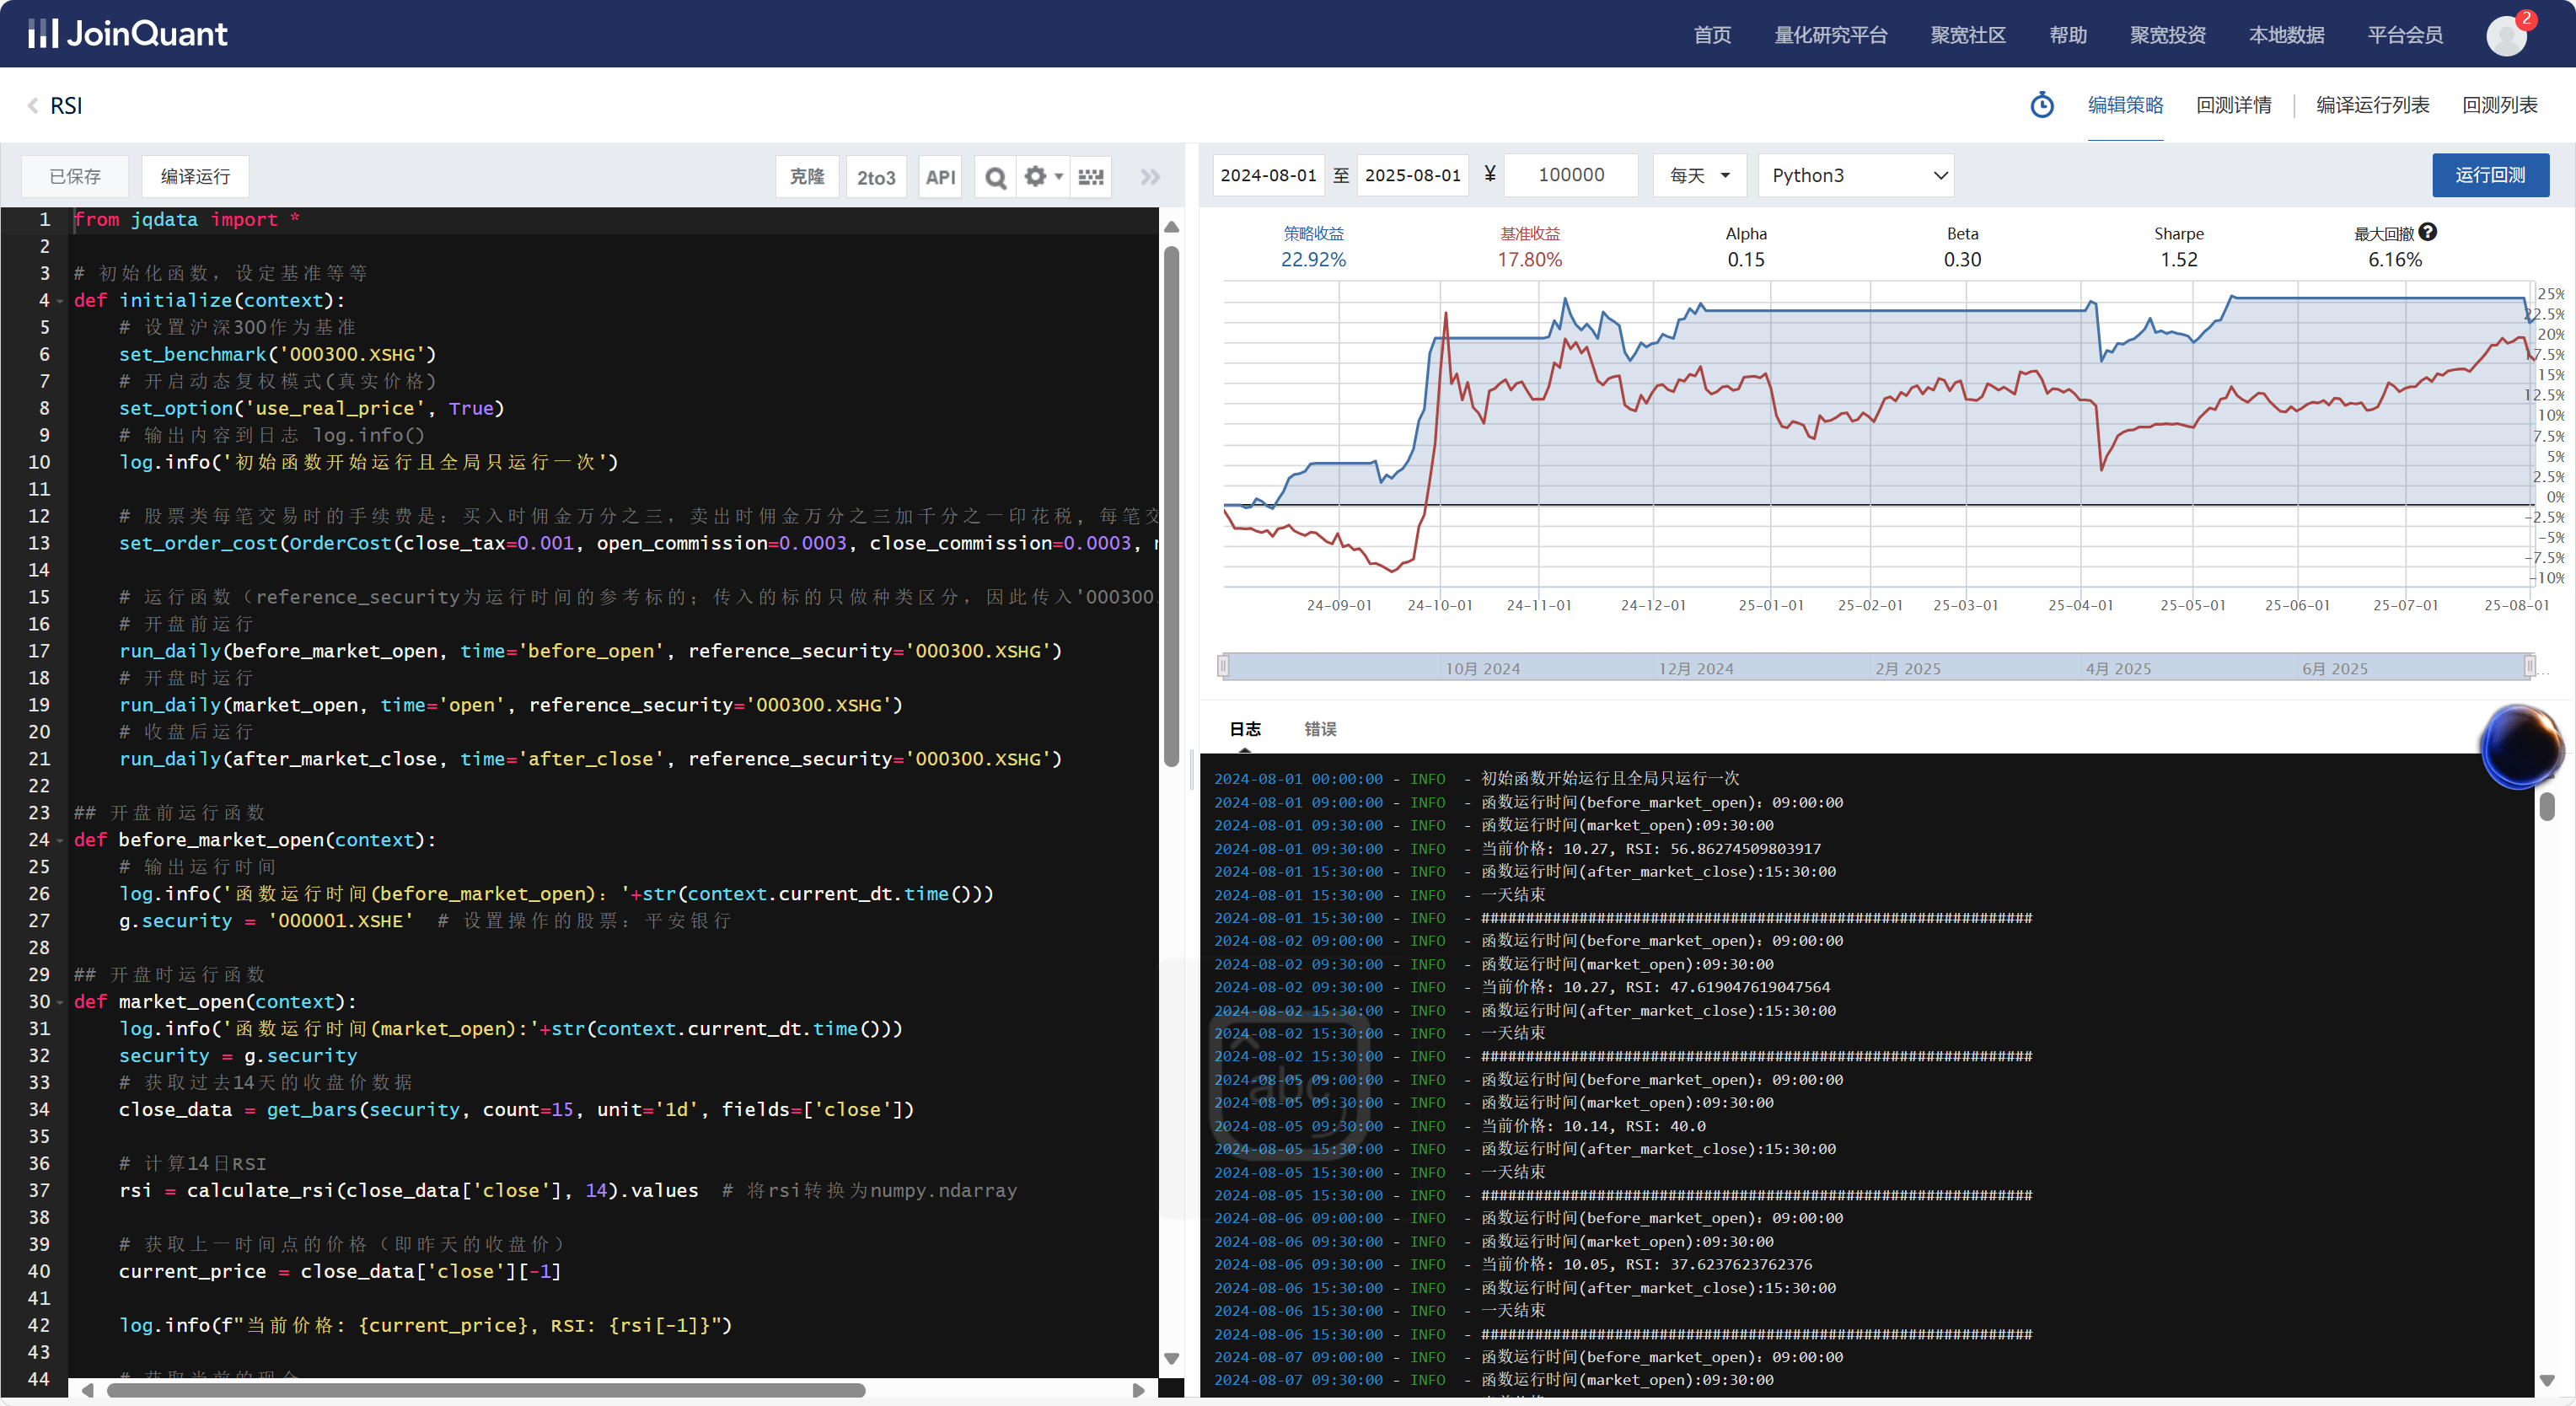

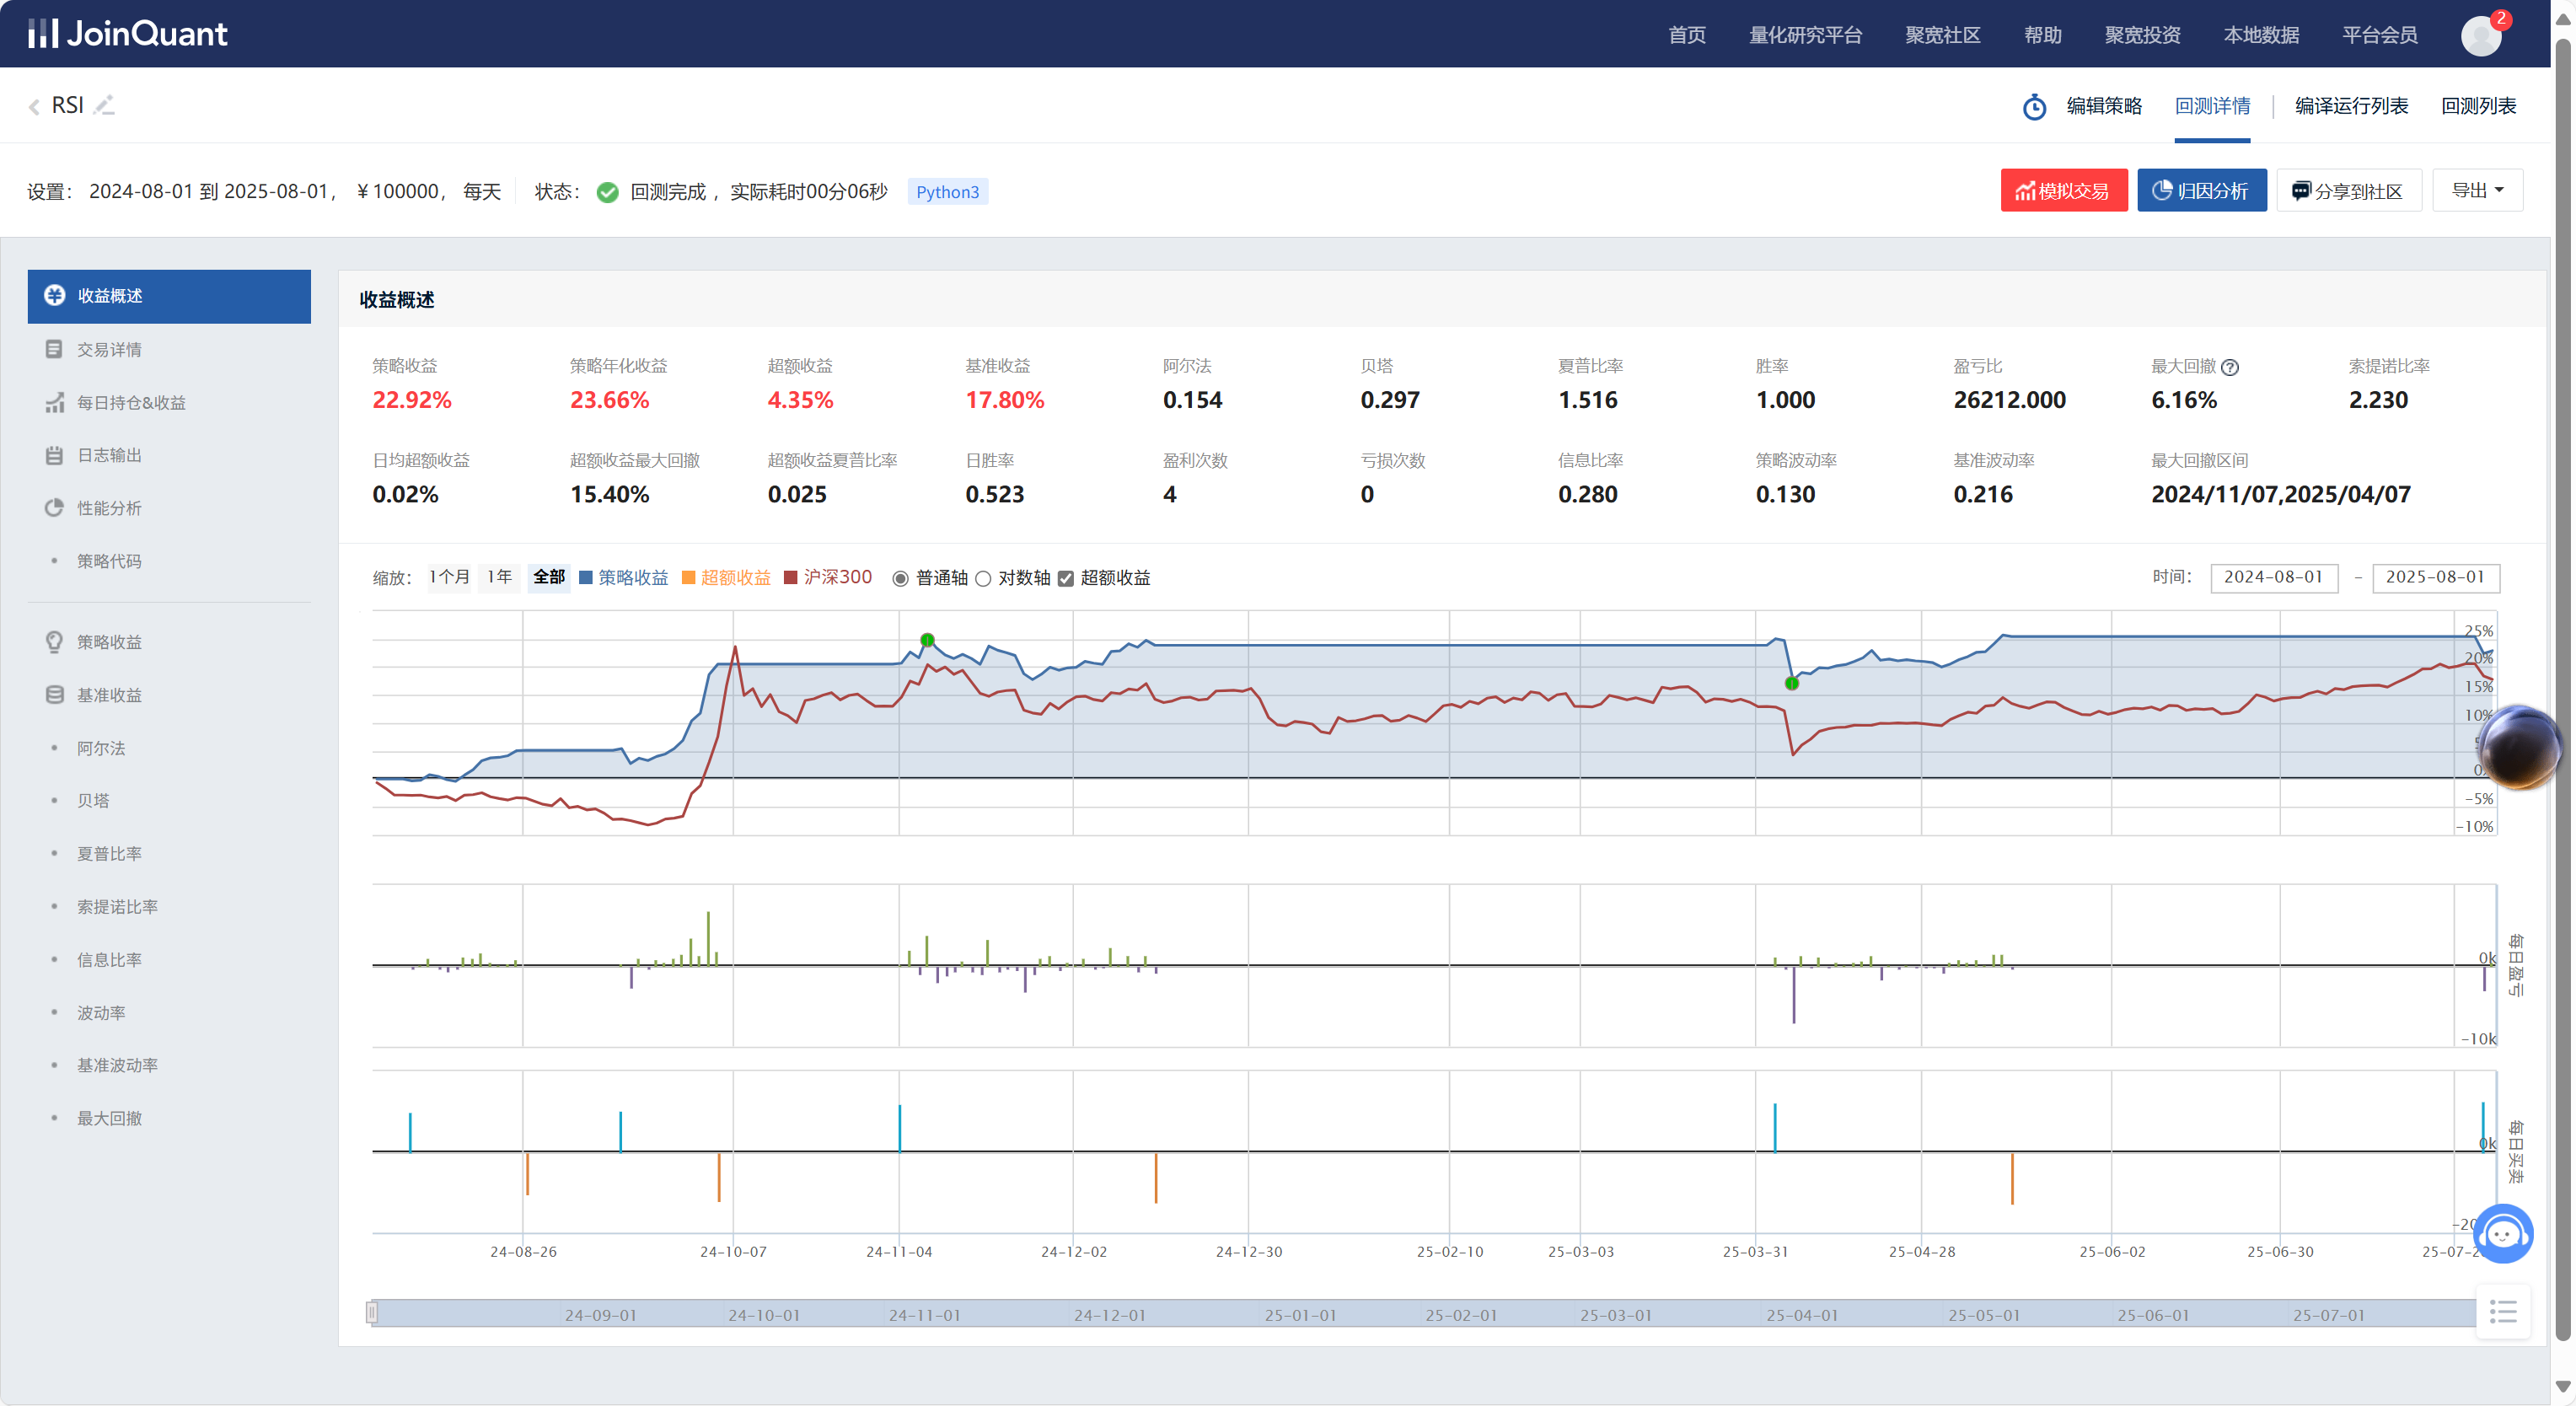



* **策略年化收益 (23.66%)** vs **基准收益 (4.35%)**
* **结论：** 策略在回测期内（2024-08-01 至 2025-08-01）的表现远超同期沪深300指数。它不仅赚钱了，而且赚到了远超市场平均水平的钱。

* **Alpha (阿尔法): 17.80%**
    * **分析：** 这是一个非常高的Alpha值。Alpha代表策略*独立于市场*的超额收益。这说明其中23.66%的收益中，有高达17.80%是*真正*来自于RSI指标的择时能力，而不是“跟涨抗跌”带来的。

* **Beta (贝塔): 0.154**
    * **分析：** 这是一个极低的Beta值。Beta为1代表策略与市场同涨同跌。0.154意味着策略几乎不受大盘影响。